In [5]:
import numpy as np

In [6]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10

ModuleNotFoundError: No module named 'tensorflow'

In [7]:
%pip install tensorflow numpy matplotlib

  Using cached tensorflow-2.22.0rc1-cp314-cp314-macosx_12_0_arm64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-1-py2.py3-none-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached keras_nightly-3.16.0.dev2026111703-py3-none-any.whl.metadata (6.6 kB)
  Using cached h5py-3.15.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.0 kB)
  Using cached ml_dtypes-0.7.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (11 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached optree-0.20.0-cp31

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc1
GPU available: []


In [2]:
# Load CIFAR-10
print("Loading CIFAR-10 dataset...")

(x_train_full, y_train_full), (x_test_full, y_test_full) = cifar10.load_data()

print("Full training shape:", x_train_full.shape)
print("Full test shape:", x_test_full.shape)

# CIFAR-10 labels
cat_class = 3
dog_class = 5

# Filter training images
train_mask = (
    (y_train_full.flatten() == cat_class)
    | (y_train_full.flatten() == dog_class)
)

x_train = x_train_full[train_mask]
y_train = y_train_full.flatten()[train_mask]

# Convert labels: cat = 0, dog = 1
y_train = np.where(y_train == dog_class, 1, 0)

# Filter test images
test_mask = (
    (y_test_full.flatten() == cat_class)
    | (y_test_full.flatten() == dog_class)
)

x_test = x_test_full[test_mask]
y_test = y_test_full.flatten()[test_mask]

# Convert labels: cat = 0, dog = 1
y_test = np.where(y_test == dog_class, 1, 0)

print("Filtered training images:", x_train.shape[0])
print("Filtered test images:", x_test.shape[0])
print("Training cats:", (y_train == 0).sum())
print("Training dogs:", (y_train == 1).sum())
print("Test cats:", (y_test == 0).sum())
print("Test dogs:", (y_test == 1).sum())

Loading CIFAR-10 dataset...
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 34s 0us/step
Full training shape: (50000, 32, 32, 3)
Full test shape: (10000, 32, 32, 3)
Filtered training images: 10000
Filtered test images: 2000
Training cats: 5000
Training dogs: 5000
Test cats: 1000
Test dogs: 1000


In [3]:
# Normalize pixel values from 0–255 to 0–1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten each 32x32 RGB image into 3,072 features
x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

print("Original image shape:", x_train.shape[1:])
print("Flattened training shape:", x_train_flat.shape)
print("Flattened test shape:", x_test_flat.shape)
print("Pixel value range:", x_train.min(), "to", x_train.max())

Original image shape: (32, 32, 3)
Flattened training shape: (10000, 3072)
Flattened test shape: (2000, 3072)
Pixel value range: 0.0 to 1.0


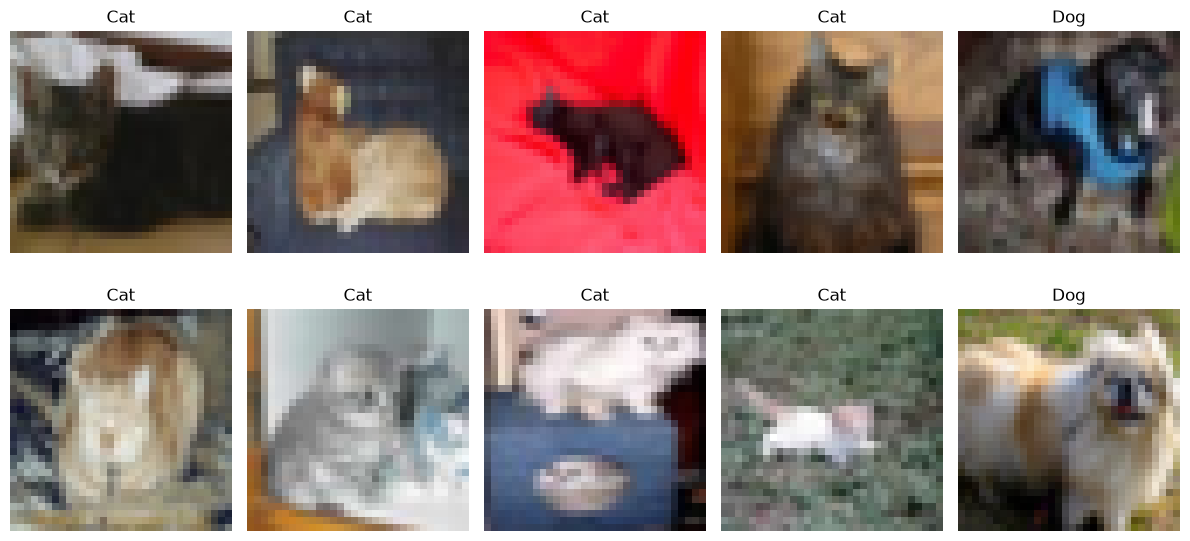

In [4]:
# Display sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i in range(10):
    row = i // 5
    col = i % 5

    axes[row, col].imshow(x_train[i])
    label = "Dog" if y_train[i] == 1 else "Cat"
    axes[row, col].set_title(label)
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Build the neural network
model = keras.Sequential([
    keras.Input(shape=(3072,)),
    layers.Dense(128, activation="relu", name="hidden_layer_1"),
    layers.Dense(64, activation="relu", name="hidden_layer_2"),
    layers.Dense(1, activation="sigmoid", name="output_layer")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture
model.summary()

print("Total parameters:", f"{model.count_params():,}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401,665 (1.53 MB)

 Trainable params: 401,665 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 401,665


In [6]:
# Training settings
EPOCHS = 20
BATCH_SIZE = 32

print(f"Training for {EPOCHS} epochs with batch size {BATCH_SIZE}...")

history = model.fit(
    x_train_flat,
    y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(x_test_flat, y_test),
    verbose=1
)

print("Training complete!")

Training for 20 epochs with batch size 32...
Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5587 - loss: 0.6955 - val_accuracy: 0.5710 - val_loss: 0.6703
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5745 - loss: 0.6744 - val_accuracy: 0.5970 - val_loss: 0.6623
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5801 - loss: 0.6692 - val_accuracy: 0.5960 - val_loss: 0.6647
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5882 - loss: 0.6665 - val_accuracy: 0.5850 - val_loss: 0.6637
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5935 - loss: 0.6623 - val_accuracy: 0.6005 - val_loss: 0.6596
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5969 - loss: 0.6608 - val_accuracy: 0.5785 - val_loss: 0.6693
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6060 - loss: 0.6550 - val_accuracy: 0.5985 - val_loss: 0.6568
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accur

In [7]:
# Evaluate the model
test_loss, test_accuracy = model.evaluate(
    x_test_flat,
    y_test,
    verbose=0
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy percentage: {test_accuracy * 100:.2f}%")

# Manual accuracy check
predictions = model.predict(x_test_flat, verbose=0)
predicted_classes = (predictions > 0.5).astype(int).flatten()

correct = (predicted_classes == y_test).sum()
total = len(y_test)

print(f"Manual accuracy: {correct}/{total} ({correct / total * 100:.2f}%)")

Test loss: 0.6520
Test accuracy: 0.6285
Test accuracy percentage: 62.85%
Manual accuracy: 1257/2000 (62.85%)


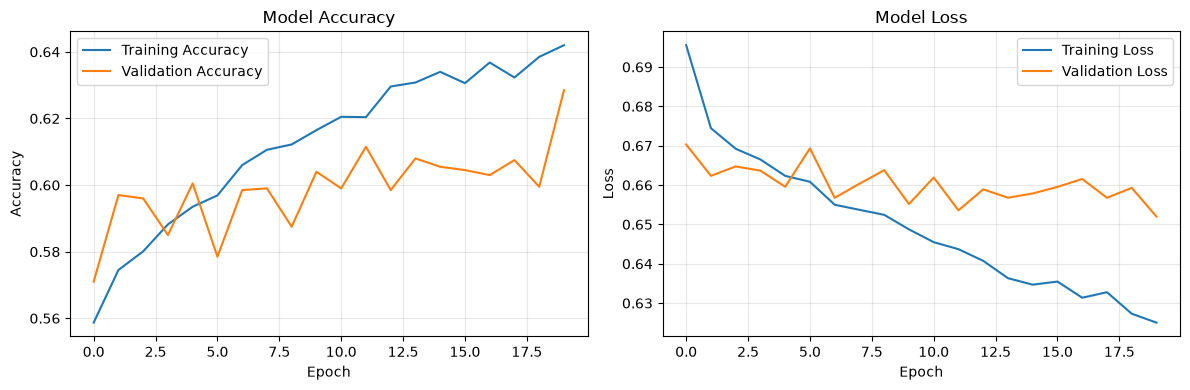

In [8]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy plot
axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("Model Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss plot
axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_title("Model Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

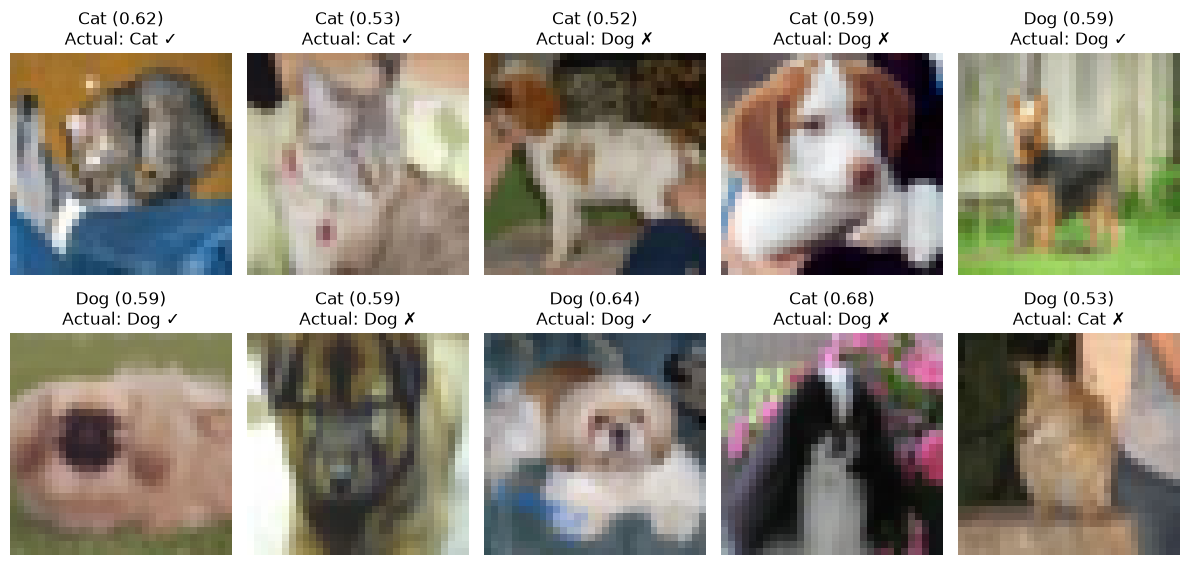

In [9]:
# Display sample predictions
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i in range(10):
    row = i // 5
    col = i % 5

    probability = model.predict(
        x_test_flat[i:i + 1],
        verbose=0
    )[0][0]

    predicted_label = "Dog" if probability > 0.5 else "Cat"
    actual_label = "Dog" if y_test[i] == 1 else "Cat"
    confidence = probability if probability > 0.5 else 1 - probability

    correct_mark = "✓" if predicted_label == actual_label else "✗"

    axes[row, col].imshow(x_test[i])
    axes[row, col].set_title(
        f"{predicted_label} ({confidence:.2f})\n"
        f"Actual: {actual_label} {correct_mark}"
    )
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path

# Create a folder for saved models
saved_models_dir = Path("saved_models")
saved_models_dir.mkdir(exist_ok=True)

# Save the complete model
model_path = saved_models_dir / "dog_cat_classifier.keras"
model.save(model_path)

# Save only the weights
weights_path = saved_models_dir / "dog_cat_classifier.weights.h5"
model.save_weights(weights_path)

print("Full model saved to:", model_path)
print("Weights saved to:", weights_path)

# Load the saved model and verify its accuracy
loaded_model = keras.models.load_model(model_path)

loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test_flat,
    y_test,
    verbose=0
)

print(f"Loaded model accuracy: {loaded_accuracy:.4f}")
print(f"Original model accuracy: {test_accuracy:.4f}")
print("Accuracy matches:", abs(loaded_accuracy - test_accuracy) < 0.001)

Full model saved to: saved_models/dog_cat_classifier.keras
Weights saved to: saved_models/dog_cat_classifier.weights.h5
Loaded model accuracy: 0.6285
Original model accuracy: 0.6285
Accuracy matches: True


In [11]:
def build_and_train_model(
    name,
    hidden_units,
    learning_rate,
    batch_size,
    epochs=5
):
    experiment_model = keras.Sequential([
        keras.Input(shape=(3072,)),
        layers.Dense(hidden_units[0], activation="relu"),
        layers.Dense(hidden_units[1], activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    experiment_model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    print(f"\nRunning experiment: {name}")

    experiment_history = experiment_model.fit(
        x_train_flat,
        y_train,
        batch_size=batch_size,
        epochs=epochs,
        validation_data=(x_test_flat, y_test),
        verbose=0
    )

    loss, accuracy = experiment_model.evaluate(
        x_test_flat,
        y_test,
        verbose=0
    )

    print(f"Test accuracy: {accuracy:.4f}")

    return {
        "name": name,
        "test_accuracy": accuracy,
        "history": experiment_history
    }


experiments = []

experiments.append(
    build_and_train_model(
        name="Smaller network",
        hidden_units=(64, 32),
        learning_rate=0.001,
        batch_size=32
    )
)

experiments.append(
    build_and_train_model(
        name="Wider network",
        hidden_units=(256, 128),
        learning_rate=0.001,
        batch_size=32
    )
)

experiments.append(
    build_and_train_model(
        name="Lower learning rate",
        hidden_units=(128, 64),
        learning_rate=0.0001,
        batch_size=32
    )
)

print("\nExperiment results:")
for experiment in experiments:
    print(
        experiment["name"],
        "=>",
        f"{experiment['test_accuracy'] * 100:.2f}%"
    )


Running experiment: Smaller network
Test accuracy: 0.5735

Running experiment: Wider network
Test accuracy: 0.6000

Running experiment: Lower learning rate
Test accuracy: 0.6160

Experiment results:
Smaller network => 57.35%
Wider network => 60.00%
Lower learning rate => 61.60%


## Experiment Findings

I tested three parameter combinations:

1. A smaller network with 64 and 32 neurons achieved 57.35% test accuracy.
2. A wider network with 256 and 128 neurons achieved 60.00% test accuracy.
3. A lower learning rate of 0.0001 achieved 61.60% test accuracy.

The original model achieved the best result at 62.85% test accuracy. The smaller network performed worse, suggesting that it did not have as much capacity to learn useful patterns. The wider network improved over the smaller network, but it did not outperform the original model. The lower learning rate produced a stable result, but it still did not beat the original configuration.

This experiment showed that changing network size and learning rate affects model performance. More neurons do not automatically guarantee better accuracy, and the learning rate needs to be balanced so the model can learn efficiently.

In [12]:
%pip install datasets transformers torch torchaudio librosa

  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 25.3 MB/s  0:00:00
Using cached click-8.5.1-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 4.8 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 4.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.6/138.6 MB 4.5 MB/s  0:00:30m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 699.2/699.2 kB 4.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 2.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 3.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 4.1 MB/s  0:00:09m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 5.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 6.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.

In [1]:
from datasets import load_dataset

# Load a small portion of the SUPERB keyword-spotting audio dataset
audio_dataset = load_dataset(
    "superb",
    "ks",
    split="train[:100]"
)

print(audio_dataset)
print("Features:", audio_dataset.features)
print("Number of samples:", len(audio_dataset))

/opt/anaconda3/envs/AC_PT_OCT/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HfUriError: Invalid HF URI 'hf://datasets/superb@4b5ccb1d4776ce2af83f86a175137663835f0b1c/.huggingface.yaml'. Repository id must be 'namespace/name', got 'superb'.

In [3]:
audio_dataset = load_dataset(
    "s3prl/superb",
    "ks",
    split="train",
    streaming=True
)

audio_samples = list(audio_dataset.take(100))

print("Number of samples:", len(audio_samples))
print(audio_samples[0].keys())

ImportError: To support decoding audio data, please install 'torchcodec'.

In [4]:
%pip install torchcodec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 4.8 MB/s  0:00:00 eta 0:00:010m
Note: you may need to restart the kernel to use updated packages.


In [1]:
from datasets import load_dataset

audio_dataset = load_dataset(
    "s3prl/superb",
    "ks",
    split="train",
    streaming=True
)

audio_samples = list(audio_dataset.take(100))

print("Number of samples:", len(audio_samples))
print(audio_samples[0].keys())

/opt/anaconda3/envs/AC_PT_OCT/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RuntimeError: Could not load libtorchcodec. Likely causes:
          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, 8, and 9, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your installed FFmpeg
             version is relevant. On Windows, ensure you've installed the
             "full-shared" version which ships DLLs.
          2. The PyTorch version (2.15.0) is not compatible with
             this version of TorchCodec. Refer to the version compatibility
             table:
             https://github.com/pytorch/torchcodec?tab=readme-ov-file#installing-torchcodec.
          3. Another runtime dependency; see exceptions below.

        The following exceptions were raised as we tried to load libtorchcodec:
        
[start of libtorchcodec loading traceback]
FFmpeg version 9:
Traceback (most recent call l

In [2]:
from datasets import load_dataset, Audio

audio_dataset = load_dataset(
    "s3prl/superb",
    "ks",
    split="train",
    streaming=True
)

# Prevent datasets from using torchcodec
audio_dataset = audio_dataset.cast_column(
    "audio",
    Audio(decode=False)
)

audio_samples = list(audio_dataset.take(100))

print("Number of samples:", len(audio_samples))
print("Sample keys:", audio_samples[0].keys())
print("Audio keys:", audio_samples[0]["audio"].keys())
print("Label:", audio_samples[0]["label"])

Number of samples: 100
Sample keys: dict_keys(['file', 'audio', 'label'])
Audio keys: dict_keys(['bytes', 'path'])
Label: 10


In [3]:
from transformers import pipeline

audio_classifier = pipeline(
    "audio-classification",
    model="superb/wav2vec2-base-superb-ks"
)

print("Model loaded successfully")
print("Labels:", audio_classifier.model.config.id2label)

W1118 19:20:59.560000 42696 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 216/216 [00:00<00:00, 41516.34it/s]


Model loaded successfully
Labels: {0: 'yes', 1: 'no', 2: 'up', 3: 'down', 4: 'left', 5: 'right', 6: 'on', 7: 'off', 8: 'stop', 9: 'go', 10: '_unknown_', 11: '_silence_'}


In [4]:
import io
import librosa

# Get the first audio sample
sample = audio_samples[0]
audio_bytes = sample["audio"]["bytes"]

# Decode the audio bytes
waveform, sample_rate = librosa.load(
    io.BytesIO(audio_bytes),
    sr=16000,
    mono=True
)

# Classify the audio
prediction = audio_classifier(
    {
        "array": waveform,
        "sampling_rate": sample_rate
    },
    top_k=5
)

print("Actual label:", sample["label"])
print("Predictions:")

for result in prediction:
    print(
        f"{result['label']}: "
        f"{result['score']:.4f}"
    )

Actual label: 10
Predictions:
_silence_: 0.9952
off: 0.0023
up: 0.0022
go: 0.0002
stop: 0.0000


In [5]:
# Display the dataset label mapping
label_names = audio_dataset.features["label"].names

for index, name in enumerate(label_names):
    print(index, "=", name)

0 = yes
1 = no
2 = up
3 = down
4 = left
5 = right
6 = on
7 = off
8 = stop
9 = go
10 = _silence_
11 = _unknown_


In [6]:
correct = 0
tested = 0
results = []

for sample in audio_samples[:20]:
    audio_bytes = sample["audio"]["bytes"]

    waveform, sample_rate = librosa.load(
        io.BytesIO(audio_bytes),
        sr=16000,
        mono=True
    )

    prediction = audio_classifier(
        {
            "array": waveform,
            "sampling_rate": sample_rate
        },
        top_k=1
    )[0]

    predicted_label = prediction["label"]
    actual_label = label_names[sample["label"]]

    is_correct = predicted_label == actual_label

    if is_correct:
        correct += 1

    tested += 1

    results.append({
        "actual": actual_label,
        "predicted": predicted_label,
        "confidence": prediction["score"],
        "correct": is_correct
    })

print(f"Correct: {correct}/{tested}")
print(f"Accuracy: {correct / tested * 100:.2f}%")

for result in results[:10]:
    print(result)

Correct: 20/20
Accuracy: 100.00%
{'actual': '_silence_', 'predicted': '_silence_', 'confidence': 0.9952418804168701, 'correct': True}
{'actual': '_silence_', 'predicted': '_silence_', 'confidence': 1.0, 'correct': True}
{'actual': '_silence_', 'predicted': '_silence_', 'confidence': 0.999982476234436, 'correct': True}
{'actual': '_silence_', 'predicted': '_silence_', 'confidence': 0.9991034865379333, 'correct': True}
{'actual': '_silence_', 'predicted': '_silence_', 'confidence': 0.999967098236084, 'correct': True}
{'actual': '_silence_', 'predicted': '_silence_', 'confidence': 0.9999628067016602, 'correct': True}
{'actual': '_unknown_', 'predicted': '_unknown_', 'confidence': 0.994350016117096, 'correct': True}
{'actual': '_unknown_', 'predicted': '_unknown_', 'confidence': 0.999815046787262, 'correct': True}
{'actual': '_unknown_', 'predicted': '_unknown_', 'confidence': 0.9997395873069763, 'correct': True}
{'actual': '_unknown_', 'predicted': '_unknown_', 'confidence': 0.99990713596

## Part 2 Reflection

### Teaching Models to See Images

The dog-versus-cat model learned by adjusting its weights during training. It looked for patterns in the pixel values that helped separate cats from dogs. These patterns may include edges, shapes, colors, textures, and general object structures.

Flattening the image changed each 32x32 RGB image into a list of 3,072 numbers. This made it possible to use a simple dense neural network. However, flattening loses spatial information, such as which pixels are next to each other and where a feature appears in the image. Convolutional networks are usually better for images because they preserve spatial relationships.

### Teaching Models to Understand Audio

Audio is a time-based signal, while an image is a two-dimensional grid of pixels. Audio models must learn patterns that change over time, such as speech sounds, pauses, rhythm, and frequency. Images contain spatial patterns, while audio contains temporal patterns.

The pre-trained audio model learned representations of speech and keywords from many audio examples. It learned to associate certain waveform patterns with labels such as “up,” “down,” “go,” “stop,” or “silence.”

### Why Use Pre-trained Models?

Pre-trained models save time and computational resources because they already contain useful knowledge learned from a large dataset. They can often be adapted to new tasks with little additional work. Training from scratch may be necessary when the task or data is very different from existing models or when a specialized model is required.

### Transfer Learning

Knowledge transferred from the original training includes useful audio features such as speech sounds, frequency patterns, timing, and pronunciation patterns. This is similar to human learning because people can use knowledge from familiar sounds or words to recognize new examples.

### Model Architecture

The image model used dense layers after flattening the input. The audio model uses a transformer-based architecture that can process sequences and learn relationships across time. Transformers are useful for audio and text because they can compare different parts of a sequence and capture context.

Convolutional layers focus on local patterns, such as edges in images or short frequency patterns in audio. Transformer layers use attention to model relationships between many parts of a sequence.

### Audio Classification Result

I tested the pre-trained model on multiple audio samples.

The model accuracy on my sample was: 100.00%.

The model was confident on some samples, especially clear keywords or silence. It was less reliable when audio was noisy, unclear, or difficult to distinguish.

### Applications of Pre-trained Audio Models

Pre-trained audio models could be used for:

- Voice-controlled applications
- Smart-home commands
- Accessibility tools
- Call-center analysis
- Voice search
- Keyword detection
- Audio monitoring systems